<h1>EN 3160 - Assignment 3</h1>
<h2>Neural Networks</h2>
<h3>Index No. - 230013A</h3>
<h3>Name - D. H. Abeywarna</h3>
Github - <a href="https://github.com/dilith813/en3160-a03">https://github.com/dilith813/en3160-a03</a>

# Question 1

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='../data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='../data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

First, the CIFAR-10 dataset was loaded. It has 50 000 training and 10 000 test colour images of 32x32 pixels, belonging to 10 classes. They were preprocessed, being converted into tensors and normalized to [-1,1]. Each image is flattened into a vector of 3072 (32x32x3) values. Since the images are processed in batches of size 50, an epoch would have 1000 weight updates.

In [14]:
# 2. Define Network Parameters
Din = 3 * 32 * 32      # Input size (flattened CIFAR-10 image size)
K = 10                 # Output size (number of classes in CIFAR-10)
std = 1e-2             # Value was changed from 1e-5 (to better suit two layers)

# Define Middle Layer Parameters (Q1 (a))
H = 100                                  # number of nodes in the middle layer
torch.manual_seed(0)                     # added for reproducibility
w1 = torch.randn(Din, H) * std           # layer 1: input -> middle
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std             # layer 2: middle -> output
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # 10 epochs
lr = 0.05         # Learning rate
lr_decay = 0.9      # Learning rate decay
reg = 0             # Regularization
loss_history = []

### Q1(a): Network architecture
The single dense layer of Listing 1 was replaced by two layers:

$$z_1 = xW_1 + b_1,\quad h = \sigma(z_1),\quad \hat y = hW_2 + b_2$$

with $x\in\mathbb{R}^{3072}$, $h\in\mathbb{R}^{100}$ and $\hat y\in\mathbb{R}^{10}$, where
$\sigma(z)=1/(1+e^{-z})$. This gives 3072·100 + 100 + 100·10 + 10 = 308,310 trainable parameters.
Weights were initialised from a normal distribution with std 0.01 and biases to zero.

Random weights break the symmetry between hidden nodes, which would otherwise all receive identical
gradients.

The sigmoid adds non-linearity. Without it, the two stacked linear layers would
collapse into one linear map.

**Hyperparameters.** Batch size 50, 10 epochs, learning rate 0.05 decayed by 0.9 after each
epoch, no regularization (reg = 0). The listing's values (std = 1e-5, lr = 2e-6) were designed
for a single linear layer. With lr = 2e-6 the loss stayed at about 2.3036 for all 10 epochs
(ln 10 ≈ 2.3026, the loss of a uniform guess), so the network did not learn. The updates were
too small. lr = 0.05 was chosen because it trains smoothly; it was not tuned further.

In [15]:
# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                                           # Batch size
        x_train = inputs.view(Ntr, -1)                                  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()       # Convert labels to one-hot

        # Forward Pass with 2 layers
        z1 = x_train.mm(w1) + b1                                        # middle layer pre-activation
        h = 1.0 / (1.0 + torch.exp(-z1))                                # sigmoid activation
        y_pred = h.mm(w2) + b2                                          # output layer scores (logits)

        # Calculating Cross-Entropy Loss
        z = y_pred - y_pred.max(dim=1, keepdim=True).values
        e = torch.exp(z)
        p = e / e.sum(dim=1, keepdim=True)                              # softmax probabilities
        loss = -torch.log(p[torch.arange(Ntr), labels]).mean() \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))        # cross-entropy + regularisation

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (p - y_train_onehot) / Ntr                            # softmax + cross-entropy gradient

        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())                                         # push gradient back through w2
        dz1 = dh * h * (1 - h)                                          # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w2 -= lr * dw2
        b2 -= lr * db2
        w1 -= lr * dw1
        b1 -= lr * db1

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

print(f"Loss before any learning: {loss_history[0]}")

Epoch 1/10, Loss: 1.983628683924675
Epoch 2/10, Loss: 1.7916365011930466
Epoch 3/10, Loss: 1.7248878792524338
Epoch 4/10, Loss: 1.6850644743442535
Epoch 5/10, Loss: 1.6558336367607116
Epoch 6/10, Loss: 1.63202667927742
Epoch 7/10, Loss: 1.612223219871521
Epoch 8/10, Loss: 1.5950423702001573
Epoch 9/10, Loss: 1.5796113493442536
Epoch 10/10, Loss: 1.5665409650802613
Loss before any learning: 2.3027901649475098


### Q1(a): Backpropagation through the two layers
The gradient is propagated backwards with the chain rule:

$$dW_2 = h^\top d\hat y,\quad db_2=\sum d\hat y,\quad dh = d\hat y\,W_2^\top$$
$$dz_1 = dh\odot h\odot(1-h),\quad dW_1 = x^\top dz_1,\quad db_1=\sum dz_1$$

The factor $h(1-h)$ is the sigmoid derivative $\sigma'(z)=\sigma(z)(1-\sigma(z))$. Each backward
line mirrors one forward line: a matrix product $aW$ gives $dW=a^\top dz$ and $da=dz\,W^\top$.
Parameters are then updated by plain gradient descent, $W \leftarrow W - \eta\,dW$.

### Q1(b): Cross-entropy loss
The scores are converted to probabilities with softmax,

$$p_k = \frac{e^{\hat y_k}}{\sum_j e^{\hat y_j}}$$

The largest score is subtracted first so that the exponentials don't overflow. This does not affect the result.

Cross-Entropy loss only looks at the probability given to the correct class and penalizes it for being small.

$$L = -\frac{1}{N}\sum_{n} \ln p_{n,\text{correct}}$$

(For example, if the correct class gets probability 0.9 the loss for that image is 0.11; if it gets 0.1, the loss would be 2.30. When training starts, all 10 classes start at about 10% probability. So, the loss would start at $\approx2.30$, as observed above.)

Combining softmax and cross-entropy gives a gradient of (predicted probabilities - one-hot labels). In code: 'dy_pred = (p - y_onehot) / N'. This replaces the MSE gradient of the listing, $(2/N)(\hat y - y)$.

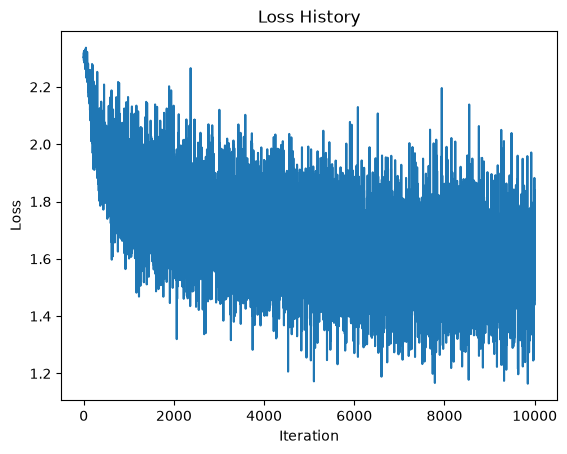

In [16]:
# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

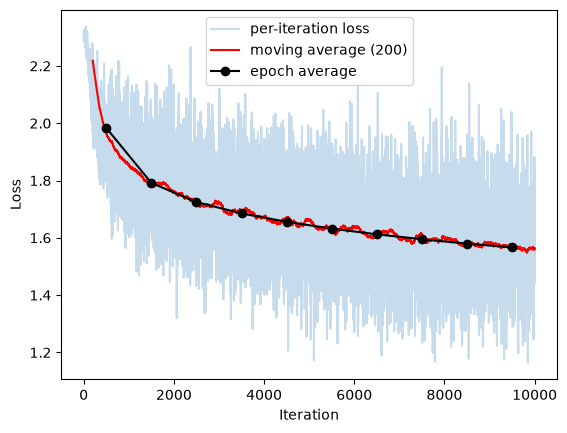

first 100 iterations, mean loss: 2.280981769561768
last 1000 iterations, mean loss: 1.5665409650802613
per-iteration std in last 1000: 0.1362109500779254


In [19]:
# Smoothed Loss History (For better visualization of trend)
import numpy as np

lh = np.array(loss_history)
win = 200                                          # moving-average window (iterations)
smooth = np.convolve(lh, np.ones(win) / win, mode='valid')
epoch_avg = lh.reshape(10, -1).mean(axis=1)        # 1,000 updates per epoch

plt.plot(lh, alpha=0.25, label='per-iteration loss')
plt.plot(np.arange(win - 1, len(lh)), smooth, 'r', label=f'moving average ({win})')
plt.plot(np.arange(10) * 1000 + 500, epoch_avg, 'ko-', label='epoch average')
plt.xlabel('Iteration'); plt.ylabel('Loss'); plt.legend(); plt.show()

print("first 100 iterations, mean loss:", lh[:100].mean())
print("last 1000 iterations, mean loss:", lh[-1000:].mean())
print("per-iteration std in last 1000:", lh[-1000:].std())

The loss starts at about 2.3 and drops quickly over the first few hundred iterations, then
keeps falling slowly. The raw curve is very noisy because each point is the loss on only 50 images, and some batches are easier than others.
The moving average shows the trend underneath, and the epoch averages fall from 1.98 to
1.57. The improvement per epoch shrinks (about 0.19 after the first epoch, about 0.01 at the
end), so training is slowing down, helped by the decaying learning rate, but it has not fully
converged within the 10 epochs.

In [17]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass through both layers
        h = 1.0 / (1.0 + torch.exp(-(x_train.mm(w1) + b1)))
        y_train_pred = h.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
train_acc = 100 * correct_train / total_train
# Calculate Training Accuracy (Q1 (c))
print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 46.48%


In [18]:
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass through both layers
        h = 1.0 / (1.0 + torch.exp(-(x_test.mm(w1) + b1)))
        y_test_pred = h.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
# Calculate Test Accuracy (Q1 (c))
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 44.73%


### Q1(c): Results after 10 epochs

| | Accuracy |
|---|---|
| Training | 46.48% |
| Test | 44.73% |

Both are well above the 10% chance level, so the network learned. The gap is only about
1.75 points, so there is no sign of overfitting. The accuracy is low because flattening the
image into a vector throws away its 2-D structure. So, the network cannot detect local patterns
such as edges or shapes, and every pixel is treated as an unrelated input.

# Question 2

In [20]:
import torch.nn.functional as F
import time
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 0.1307 and 0.3081 are the mean and std of all MNIST pixels
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
mnist_train = torchvision.datasets.MNIST('../data', train=True,  download=True, transform=mnist_tf)
mnist_test  = torchvision.datasets.MNIST('../data', train=False, download=True, transform=mnist_tf)

# num_workers=2 as in the assignment's listing; set both to 0 if the cell hangs on Windows
mnist_trainloader = torch.utils.data.DataLoader(mnist_train, batch_size=64,  shuffle=True,  num_workers=2)
mnist_testloader  = torch.utils.data.DataLoader(mnist_test,  batch_size=256, shuffle=False, num_workers=2)
print(len(mnist_train), len(mnist_test))

Device: cuda
60000 10000


In [21]:
# Q2(a) - LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, 5, padding=2)    # 28x28 -> 28x28 (padding=2 mimics LeNet's 32x32 input)
        self.c2 = nn.Conv2d(6, 16, 5)              # 14x14 -> 10x10
        self.f1 = nn.Linear(16 * 5 * 5, 120)
        self.f2 = nn.Linear(120, 84)
        self.f3 = nn.Linear(84, 10)
    def forward(self, x):
        x = F.avg_pool2d(torch.tanh(self.c1(x)), 2)    # -> 6 x 14 x 14
        x = F.avg_pool2d(torch.tanh(self.c2(x)), 2)    # -> 16 x 5 x 5
        x = x.flatten(1)
        x = torch.tanh(self.f1(x))
        x = torch.tanh(self.f2(x))
        return self.f3(x)                              # 10 raw scores

# Q2(b) - Modern small CNN: 3 conv layers + batch norm + dropout
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):                               # conv -> batch norm -> ReLU -> downsample
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                                 nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))  # 28 -> 14 -> 7 -> 3
        self.drop = nn.Dropout(0.5)
        self.fc = nn.Linear(128 * 3 * 3, 10)
    def forward(self, x):
        return self.fc(self.drop(self.features(x).flatten(1)))

print("LeNet-5 parameters:", sum(p.numel() for p in LeNet5().parameters()))
print("SmallCNN parameters:", sum(p.numel() for p in SmallCNN().parameters()))

LeNet-5 parameters: 61706
SmallCNN parameters: 104650


### Q2(a) and (b): Models
**LeNet-5** (61,706 parameters): two 5×5 convolution layers (6 then 16 filters), each followed by
tanh and average pooling, then three fully connected layers (120, 84, 10). Tanh and
average pooling was used as per the original paper. Padding of 2 in the first layer lets the 28×28 MNIST
images behave like LeNet's original 32×32 input.

**Small CNN** (104,650 parameters): three 3×3 convolution blocks (32, 64, 128 filters), each
with batch normalization, ReLU and 2×2 max pooling, then dropout (p = 0.5) and one fully
connected layer. Batch normalization rescales each layer's outputs, which usually makes training
faster and more stable. Dropout randomly switches off half of the features during training, which
discourages the network from relying on any single one.

**Training conditions (identical for both):** MNIST, cross-entropy loss, Adam with learning rate
0.001, batch size 64, 10 epochs, same random seed. Train and test metrics were computed after
every epoch with dropout off.

In [22]:
def evaluate(model, loader):
    model.eval()                                       # switches off dropout, batch norm uses stored statistics
    loss_sum, correct, total, preds, truth = 0.0, 0, 0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += F.cross_entropy(out, y, reduction='sum').item()
            pred = out.argmax(1)
            correct += (pred == y).sum().item(); total += y.size(0)
            preds.append(pred.cpu()); truth.append(y.cpu())
    return loss_sum / total, 100 * correct / total, torch.cat(preds).numpy(), torch.cat(truth).numpy()

def train_model(model, epochs=10, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = dict(train_loss=[], train_acc=[], test_loss=[], test_acc=[])
    for ep in range(epochs):
        t0 = time.time()
        model.train()                                  # dropout on, batch norm uses batch statistics
        for x, y in mnist_trainloader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            F.cross_entropy(model(x), y).backward()
            opt.step()
        # Q2(c) - log loss and accuracy on both sets after every epoch (both in eval mode)
        trl, tra, _, _ = evaluate(model, mnist_trainloader)
        tel, tea, _, _ = evaluate(model, mnist_testloader)
        for key, val in zip(hist, (trl, tra, tel, tea)):
            hist[key].append(val)
        print(f"Epoch {ep+1:2d}/{epochs}  train loss {trl:.4f} acc {tra:.2f}%  |  "
              f"test loss {tel:.4f} acc {tea:.2f}%  ({time.time()-t0:.0f}s)")
    return hist

In [23]:
# Q2(a) - Train LeNet-5
torch.manual_seed(0)
lenet = LeNet5()
hist_lenet = train_model(lenet)

# Q2(b) Train SmallCNN, same optimiser, epochs, batch size and seed
torch.manual_seed(0)
small = SmallCNN()
hist_small = train_model(small)

Epoch  1/10  train loss 0.0866 acc 97.47%  |  test loss 0.0880 acc 97.38%  (36s)
Epoch  2/10  train loss 0.0505 acc 98.47%  |  test loss 0.0584 acc 98.25%  (33s)
Epoch  3/10  train loss 0.0399 acc 98.80%  |  test loss 0.0585 acc 98.28%  (33s)
Epoch  4/10  train loss 0.0313 acc 99.00%  |  test loss 0.0484 acc 98.47%  (33s)
Epoch  5/10  train loss 0.0236 acc 99.28%  |  test loss 0.0438 acc 98.62%  (30s)
Epoch  6/10  train loss 0.0191 acc 99.38%  |  test loss 0.0393 acc 98.63%  (60s)
Epoch  7/10  train loss 0.0194 acc 99.39%  |  test loss 0.0457 acc 98.59%  (55s)
Epoch  8/10  train loss 0.0170 acc 99.45%  |  test loss 0.0434 acc 98.75%  (57s)
Epoch  9/10  train loss 0.0105 acc 99.70%  |  test loss 0.0412 acc 98.62%  (54s)
Epoch 10/10  train loss 0.0130 acc 99.57%  |  test loss 0.0441 acc 98.72%  (55s)
Epoch  1/10  train loss 0.0525 acc 98.34%  |  test loss 0.0568 acc 98.33%  (56s)
Epoch  2/10  train loss 0.0275 acc 99.15%  |  test loss 0.0289 acc 99.06%  (59s)
Epoch  3/10  train loss 0.01

### Q2(a) and (b): Results after 10 epochs

| Model | Train acc | Test acc | Test errors (of 10,000) | Parameters |
|---|----------|--------|---|---|
| LeNet-5 | 99.57%   | 98.72% | 128 | 61,706 |
| Small CNN | 99.81%   | 99.26% | 70 | 104,650 |

The small CNN is better, and the improvement is clearer as it makes about 45% fewer
mistakes on the test set. However, there are two caveats. It also has about 1.7× more parameters, so the gain can't
be credited only to batch normalization and dropout. And each result is a single run with one seed,
so a difference of a few test images could change with another seed.

LeNet-5   train acc 99.57%   test acc 98.72%   test errors 128 / 10000
SmallCNN  train acc 99.81%   test acc 99.26%   test errors 74 / 10000


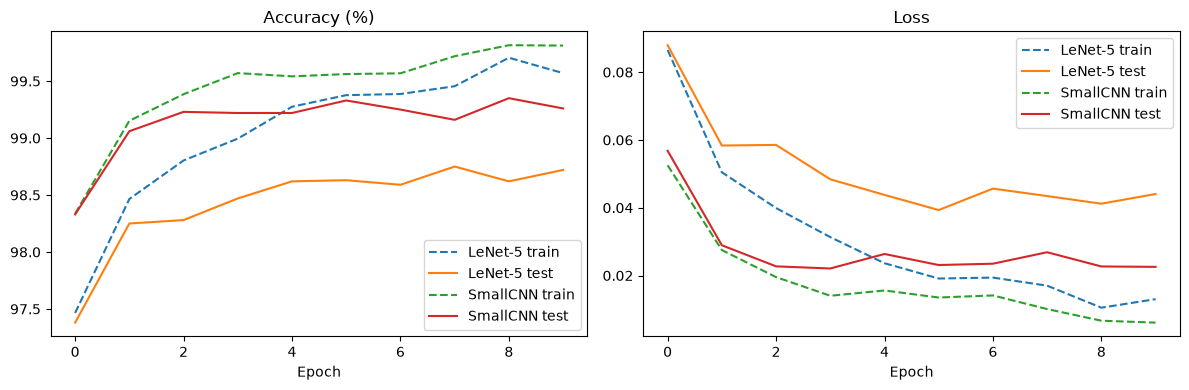

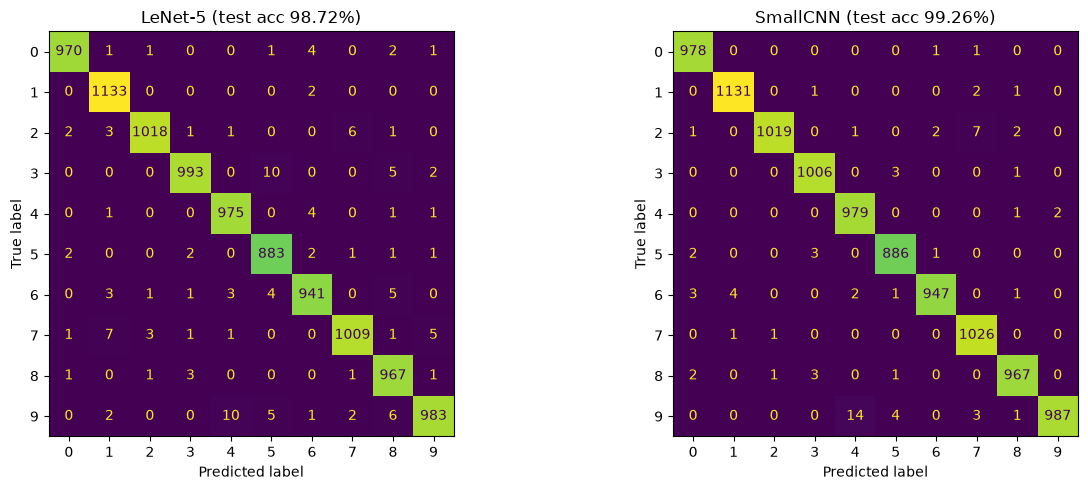

LeNet-5 top confusions (true -> predicted: count): ['3->5: 10', '9->4: 10', '7->1: 7', '2->7: 6']
SmallCNN top confusions (true -> predicted: count): ['9->4: 14', '2->7: 7', '9->5: 4', '6->1: 4']


In [24]:
# Q2(a) and Q2(b) - Final results
results = {}
for name, m in [("LeNet-5", lenet), ("SmallCNN", small)]:
    trl, tra, _, _ = evaluate(m, mnist_trainloader)
    tel, tea, pred, truth = evaluate(m, mnist_testloader)
    results[name] = (pred, truth)
    print(f"{name:9s} train acc {tra:.2f}%   test acc {tea:.2f}%   test errors {(pred != truth).sum()} / {len(truth)}")

# Q2(c) - per-epoch accuracy and loss curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [("LeNet-5", hist_lenet), ("SmallCNN", hist_small)]:
    ax[0].plot(h['train_acc'], '--', label=f"{name} train"); ax[0].plot(h['test_acc'], label=f"{name} test")
    ax[1].plot(h['train_loss'], '--', label=f"{name} train"); ax[1].plot(h['test_loss'], label=f"{name} test")
ax[0].set_title("Accuracy (%)"); ax[1].set_title("Loss")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

# Q2(c) Confusion matrices on the test set
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, name in zip(ax, results):
    pred, truth = results[name]
    ConfusionMatrixDisplay(confusion_matrix(truth, pred)).plot(ax=a, colorbar=False)
    a.set_title(f"{name} (test acc {100*(pred == truth).mean():.2f}%)")
plt.tight_layout(); plt.show()

# most frequent mistakes
for name, (pred, truth) in results.items():
    cm = confusion_matrix(truth, pred); np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(-cm, axis=None)[:4], cm.shape))[0]
    print(name, "top confusions (true -> predicted: count):",
          [f"{t}->{p}: {cm[t, p]}" for t, p in top])

### Q2(c): Training curves
Both models improve quickly in the first epochs. The small CNN is already at [98.6]% test accuracy
after one epoch, while LeNet-5 needs several epochs to pass 98.5%, which fits the faster training
that batch normalisation usually gives. The small CNN's test accuracy stays above LeNet-5's at every epoch.

LeNet-5's training loss keeps falling, but its test loss stops improving after about epoch [6]
([0.039]) and then rises slightly, so it starts to overfit mildly. The small CNN's test loss stays
roughly flat at about [0.022], and its train/test accuracy gap is smaller ([0.53] vs [0.85]
points), consistent with dropout limiting overfitting. The test curves are noisy from epoch to
epoch, so small differences between neighbouring epochs shouldn't be over-interpreted.

### Q2(c): Confusion matrices
Both matrices are strongly diagonal. The most common mistake for both models is a true **9
predicted as 4** ([10] times for LeNet-5, [14] for the small CNN); the reverse (4 predicted as 9) is
rare, so the confusion is one-directional. Handwritten 9s with a small or open loop look like a 4.
LeNet-5 also confuses [3→5] ([10]) and [7→1] ([7]) noticeably, and the small CNN almost removes
these ([2] and [1]). The pair 9→4 got slightly worse for the small CNN even though its total
errors nearly halved, so the improvement is not uniform. The 2→7 confusion is the same for both
([6]), which suggests those test digits are genuinely ambiguous.

### Q2: Summary
The small CNN gives higher test accuracy ([99.30]% vs [98.72]%), converges faster and overfits
less, at the cost of more parameters. Both are far above the dense network of Q1, but that
comparison isn't like-for-like, since Q1 used CIFAR-10 and Q2 uses MNIST. What the two experiments
do show is that convolutional layers, which look at local patterns and share weights across
positions, suit images better than a network that flattens the image into an unrelated vector.